# Desafio Final - ClearBank
Uma análise de dados a partir de um CSV, filtrando e validando as informações para encontrar dados importantes de maneira organizada.

Imports

In [99]:
import csv
import json
from datetime import datetime

Variáveis importantes

In [100]:
LIMITE_SUSPEITO = 10000.00

In [101]:
%%writefile transacoes.csv
id,data,cliente_id,tipo,valor,descricao,categoria
1,2026-01-05,CLI001,credito,3500.00,Salario janeiro,salario
2,2026-01-12,CLI002,debito,180.50,Supermercado,compra
3,2026-01-20,CLI001,debito,abc,Erro de sistema,compra
4,2026-02-03,,debito,200.00,Sem cliente,transferencia
5,2026-02-14,CLI003,credito,15000.00,Transferencia alta,transferencia
6,2026-02-18,CLI002,debito,320.00,Conta de luz,conta
7,,CLI001,credito,1000.00,ID vazio,salario
8,2026/02/25,CLI001,debito,50.00,Data formato errado,outros
9,2026-03-01,CLI001,credito,3500.00,Salario marco,salario
10,2026-03-05,CLI002,debito,120.00,Farmacia,saude
11,2026-03-10,CLI003,debito,99.90,Streaming,assinatura
12,2026-03-15,CLI004,credito,12000.00,Venda veiculo,outros
13,2026-03-20,CLI001,pix,100.00,Tipo invalido,transferencia
14,2026-03-22,CLI002,debito,45.00,Padaria,alimentacao
15,2026-03-28,CLI003,debito,-80.00,Valor negativo,compra
16,2026-01-15,CLI004,credito,2500.00,Consultoria,servico
17,2026-01-22,CLI005,debito,400.00,Combustivel,transporte
18,2026-01-28,CLI002,debito,89.90,Internet,conta
19,2026-02-05,CLI001,credito,800.00,Rendimento,investimento
20,2026-02-20,CLI005,debito,150.00,Restaurante,alimentacao
21,2026-03-12,CLI004,debito,600.00,Manutencao,servico
22,2026-03-25,CLI005,credito,1500.00,Reembolso,outros

Writing transacoes.csv


Funções

In [102]:
def ler_transacoes(caminho_arquivo="transacoes.csv"):
    transacoes_validas = []
    linhas_invalidas = 0
    total_linhas = 0

    try:
        with open(caminho_arquivo, mode="r", encoding="utf-8") as file:
            leitor = csv.DictReader(file)
            for linha in leitor:
                total_linhas += 1
                registro_limpo = validar_transacao(linha)
                if registro_limpo:
                    transacoes_validas.append(registro_limpo)
                else:
                    linhas_invalidas += 1
    except FileNotFoundError:
        print(f"Erro: O arquivo '{caminho_arquivo}' não foi encontrado.")
        return [], 0, 0

    return transacoes_validas, total_linhas, linhas_invalidas

In [103]:
def validar_transacao(linha):
    # Validação do ID: não vazio e numérico
    id_bruto = linha.get("id", "").strip()
    if not id_bruto or not id_bruto.isdigit():
        return None

    # Validação do cliente_id: não pode ser vazio
    cliente_id = linha.get("cliente_id", "").strip()
    if not cliente_id:
        return None

    # Validação e conversão da data
    try:
        data_obj = datetime.strptime(linha.get("data", "").strip(), "%Y-%m-%d")
    except (ValueError, TypeError):
        return None

    # Validação do tipo: apenas credito ou debito
    tipo = linha.get("tipo", "").strip().lower()
    if tipo not in ["credito", "debito"]:
        return None

    # Validação e conversão do valor
    try:
        valor = float(linha.get("valor", "").strip())
        if valor <= 0:
            return None
    except (ValueError, TypeError):
        return None

    return {
        "id": int(id_bruto),
        "data": data_obj,
        "cliente_id": cliente_id,
        "tipo": tipo,
        "valor": valor,
        "descricao": linha.get("descricao", "").strip(),
        "categoria": linha.get("categoria", "").strip()
    }

In [104]:
def gerar_relatorio(transacoes_validas):
    if not transacoes_validas:
        return {}, [], None, None, 0

    # Identificar data mais antiga, mais recente e dias decorridos
    datas = [t["data"] for t in transacoes_validas]
    data_mais_antiga = min(datas)
    data_mais_recente = max(datas)
    dias_totais = (data_mais_recente - data_mais_antiga).days

    resumo_mensal = {}
    transacoes_suspeitas = []

    for t in transacoes_validas:
        mes = t["data"].strftime("%Y-%m")

        if mes not in resumo_mensal:
            resumo_mensal[mes] = {
                "quantidade": 0,
                "total_credito": 0.0,
                "total_debito": 0.0,
                "saldo": 0.0,
                "media": 0.0,
                "maior_valor": t["valor"],
                "menor_valor": t["valor"],
                "_soma_total": 0.0
            }

        mes_ref = resumo_mensal[mes]
        mes_ref["quantidade"] += 1
        mes_ref["_soma_total"] += t["valor"]

        if t["tipo"] == "credito":
            mes_ref["total_credito"] += t["valor"]
        elif t["tipo"] == "debito":
            mes_ref["total_debito"] += t["valor"]

        if t["valor"] > mes_ref["maior_valor"]:
            mes_ref["maior_valor"] = t["valor"]
        if t["valor"] < mes_ref["menor_valor"]:
            mes_ref["menor_valor"] = t["valor"]

        # Identificação de suspeitas
        if t["valor"] > LIMITE_SUSPEITO:
            transacoes_suspeitas.append({
                "id": t["id"],
                "cliente_id": t["cliente_id"],
                "data": t["data"].strftime("%Y-%m-%d"),
                "valor": t["valor"]
            })

    # Finalização das métricas calculadas
    for mes, dados in resumo_mensal.items():
        dados["saldo"] = round(dados["total_credito"] - dados["total_debito"], 2)
        dados["media"] = round(dados["_soma_total"] / dados["quantidade"], 2)
        dados["total_credito"] = round(dados["total_credito"], 2)
        dados["total_debito"] = round(dados["total_debito"], 2)
        del dados["_soma_total"]

    return resumo_mensal, transacoes_suspeitas, data_mais_antiga, data_mais_recente, dias_totais

In [105]:
def formatar_moeda(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [106]:
def salvar_json(caminho_saida, resumo_mensal, total_validas, total_invalidas, transacoes_suspeitas):
    dados_json = {
        "gerado_em": datetime.now().strftime("%Y-%m-%d"),
        "total_transacoes_validas": total_validas,
        "total_transacoes_invalidas": total_invalidas,
        "resumo_mensal": resumo_mensal,
        "transacoes_suspeitas": transacoes_suspeitas
    }

    with open(caminho_saida, mode="w", encoding="utf-8") as f:
        json.dump(dados_json, f, ensure_ascii=False, indent=2)

In [107]:
def exibir_relatorio(resumo_mensal, transacoes_suspeitas, total_linhas, total_validas, total_invalidas, dt_antiga, dt_recente, dias):
    print("=" * 35)
    print("RESUMO DA LIMPEZA DOS DADOS")
    print("=" * 35)
    print(f"Total de linhas lidas: {total_linhas}")
    print(f"Linhas válidas:        {total_validas}")
    print(f"Linhas inválidas:      {total_invalidas}")

    if dt_antiga and dt_recente:
        print("\n" + "=" * 35)
        print("PERÍODO ANALISADO")
        print("=" * 35)
        print(f"De {dt_antiga.strftime('%Y-%m-%d')} até {dt_recente.strftime('%Y-%m-%d')} ({dias} dias decorridos)")

    print("\n" + "=" * 35)
    print("RELATÓRIO MENSAL")
    print("=" * 35)
    for mes in sorted(resumo_mensal.keys()):
        m = resumo_mensal[mes]
        print(f"Mês: {mes}")
        print(f"  Transações:    {m['quantidade']}")
        print(f"  Total crédito: {formatar_moeda(m['total_credito'])}")
        print(f"  Total débito:  {formatar_moeda(m['total_debito'])}")
        print(f"  Saldo:         {formatar_moeda(m['saldo'])}")
        print(f"  Valor médio:   {formatar_moeda(m['media'])}")
        print(f"  Maior valor:   {formatar_moeda(m['maior_valor'])}")
        print(f"  Menor valor:   {formatar_moeda(m['menor_valor'])}\n")

    print("=" * 35)
    print("TRANSAÇÕES SUSPEITAS")
    print("=" * 35)
    if transacoes_suspeitas:
        for s in transacoes_suspeitas:
            print(f"ID: {s['id']} | Cliente: {s['cliente_id']} | Data: {s['data']} | Valor: {formatar_moeda(s['valor'])}")
    else:
        print("Nenhuma transação suspeita encontrada.")

Estrutura do código organizada em uma célula.

In [108]:
# Execução do fluxo completo
arquivo_entrada = "transacoes.csv"
arquivo_saida = "relatorio.json"

# 1. Leitura e validação
validas, total_lidas, total_invalidas = ler_transacoes(arquivo_entrada)

# 2. Processamento e cálculo das métricas
resumo, suspeitas, dt_antiga, dt_recente, dias = gerar_relatorio(validas)

# 3. Exportação para JSON
salvar_json(arquivo_saida, resumo, len(validas), total_invalidas, suspeitas)

# 4. Exibição no terminal
exibir_relatorio(resumo, suspeitas, total_lidas, len(validas), total_invalidas, dt_antiga, dt_recente, dias)

RESUMO DA LIMPEZA DOS DADOS
Total de linhas lidas: 22
Linhas válidas:        16
Linhas inválidas:      6

PERÍODO ANALISADO
De 2026-01-05 até 2026-03-25 (79 dias decorridos)

RELATÓRIO MENSAL
Mês: 2026-01
  Transações:    5
  Total crédito: R$ 6.000,00
  Total débito:  R$ 670,40
  Saldo:         R$ 5.329,60
  Valor médio:   R$ 1.334,08
  Maior valor:   R$ 3.500,00
  Menor valor:   R$ 89,90

Mês: 2026-02
  Transações:    4
  Total crédito: R$ 15.800,00
  Total débito:  R$ 470,00
  Saldo:         R$ 15.330,00
  Valor médio:   R$ 4.067,50
  Maior valor:   R$ 15.000,00
  Menor valor:   R$ 150,00

Mês: 2026-03
  Transações:    7
  Total crédito: R$ 17.000,00
  Total débito:  R$ 864,90
  Saldo:         R$ 16.135,10
  Valor médio:   R$ 2.552,13
  Maior valor:   R$ 12.000,00
  Menor valor:   R$ 45,00

TRANSAÇÕES SUSPEITAS
ID: 5 | Cliente: CLI003 | Data: 2026-02-14 | Valor: R$ 15.000,00
ID: 12 | Cliente: CLI004 | Data: 2026-03-15 | Valor: R$ 12.000,00


## CONTEÚDO EXTRA

In [109]:
%%writefile analise_pandas.py
import pandas as pd

def executar_analise_pandas(caminho_csv="transacoes.csv"):
    df = pd.read_csv(caminho_csv)

    # Converte 'id' para numérico; inválidos viram NaN
    df["id"] = pd.to_numeric(df["id"], errors="coerce")

    # Remove registros com id ou cliente_id vazios/nulos
    df = df.dropna(subset=["id", "cliente_id"])
    df = df[df["cliente_id"].astype(str).str.strip() != ""]

    # Converte 'valor' para numérico e filtra > 0
    df["valor"] = pd.to_numeric(df["valor"], errors="coerce")
    df = df[df["valor"] > 0]

    # Validação do tipo (credito ou debito)
    df["tipo"] = df["tipo"].astype(str).str.strip().str.lower()
    df = df[df["tipo"].isin(["credito", "debito"])]

    # Converte data para datetime no formato AAAA-MM-DD
    df["data"] = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")
    df = df.dropna(subset=["data"])

    # Criação da coluna de mês (AAAA-MM)
    df["mes"] = df["data"].dt.strftime("%Y-%m")

    # Agrupamento mensal e cálculo de métricas
    resumo = {}
    for mes, grupo in df.groupby("mes"):
        credito = grupo[grupo["tipo"] == "credito"]["valor"].sum()
        debito = grupo[grupo["tipo"] == "debito"]["valor"].sum()

        resumo[mes] = {
            "quantidade": int(len(grupo)),
            "total_credito": round(float(credito), 2),
            "total_debito": round(float(debito), 2),
            "saldo": round(float(credito - debito), 2),
            "media": round(float(grupo["valor"].mean()), 2),
            "maior_valor": round(float(grupo["valor"].max()), 2),
            "menor_valor": round(float(grupo["valor"].min()), 2),
        }

    return resumo

Writing analise_pandas.py


In [110]:
import analise_pandas

# 1. Carrega os números gerados pela solução NATIVA (do arquivo JSON)
with open("relatorio.json", "r", encoding="utf-8") as f:
    dados_json = json.load(f)
resumo_nativo = dados_json["resumo_mensal"]

# 2. Executa a função que está dentro do arquivo analise_pandas.py
resumo_pandas = analise_pandas.executar_analise_pandas("transacoes.csv")

# 3. Compara os valores mês a mês
print(f"{'MÊS':<10} | {'SALDO NATIVO':<15} | {'SALDO PANDAS':<15} | {'BATEU?'}")
print("-" * 55)

for mes in resumo_nativo:
    saldo_nativo = resumo_nativo[mes]["saldo"]
    saldo_pandas = resumo_pandas[mes]["saldo"]
    bateu = "✅ Sim" if saldo_nativo == saldo_pandas else "❌ Não"

    print(f"{mes:<10} | R$ {saldo_nativo:<12.2f} | R$ {saldo_pandas:<12.2f} | {bateu}")

MÊS        | SALDO NATIVO    | SALDO PANDAS    | BATEU?
-------------------------------------------------------
2026-01    | R$ 5329.60      | R$ 5329.60      | ✅ Sim
2026-02    | R$ 15330.00     | R$ 15330.00     | ✅ Sim
2026-03    | R$ 16135.10     | R$ 16135.10     | ✅ Sim


GRÁFICO A

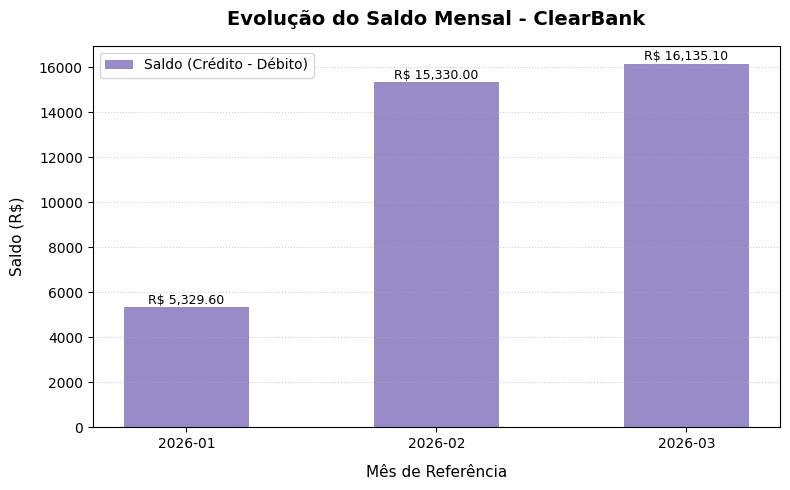

✅ Arquivo 'grafico.png' salvo com sucesso!


In [112]:
import matplotlib.pyplot as plt

# 1. Carrega os dados calculados do JSON
with open("relatorio.json", mode="r", encoding="utf-8") as f:
    dados = json.load(f)

resumo = dados["resumo_mensal"]
meses = sorted(resumo.keys())
saldos = [resumo[m]["saldo"] for m in meses]

# 2. Configuração do gráfico
plt.figure(figsize=(8, 5))
cores = ["#988BC7" if s >= 0 else "#E96379" for s in saldos]

barras = plt.bar(meses, saldos, color=cores, width=0.5, label="Saldo (Crédito - Débito)")

# 3. Título e rótulos dos eixos
plt.title("Evolução do Saldo Mensal - ClearBank", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Mês de Referência", fontsize=11, labelpad=10)
plt.ylabel("Saldo (R$)", fontsize=11, labelpad=10)
plt.axhline(0, color="gray", linewidth=0.8, linestyle="--")
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="upper left")

# Adiciona o valor em texto acima de cada barra
for barra in barras:
    yval = barra.get_height()
    offset = 600 if yval >= 0 else -300
    plt.text(barra.get_x() + barra.get_width()/2.0, yval + offset, f"R$ {yval:,.2f}", ha="center", va="bottom" if yval < 0 else "top", fontsize=9)

# 4. Salvar exatamente como 'grafico.png' e exibir
plt.tight_layout()
plt.savefig("grafico.png", dpi=300)
plt.show()

print("✅ Arquivo 'grafico.png' salvo com sucesso!")